In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import model.logistic_regression as lr

In [17]:
df = pd.read_csv("train.csv")
a = df.columns
print(a)
print(df['merchant_category'].value_counts())

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')
merchant_category
Online Retail      155097
Groceries          142578
Restaurants        101360
Fuel                59880
Electronics         48693
Streaming           47196
Utilities           42027
Healthcare          35889
Travel              28715
Gaming              23784
Gift Cards           9456
Crypto Exchange      5285
Name: count, dtype: int64


In [18]:
cat = 0
num = 0

with open("describe.txt", "w", encoding="utf-8") as f:
  for i in a:
    f.write("--------" + i + "--------" + "\n")

    if df[i].nunique() < 20:
      f.write(df[i].value_counts().to_string() + "\n")
      cat += 1
    else :
      f.write(df[i].describe().to_string() + "\n")
      num += 1
    f.write("\n")
print(cat)
print(num)

16
10


In [25]:
log_reg = lr.logistic_regression(n_epochs=80)
with open('DataSolve/output/feature_list.txt', 'r') as f:
    feature_lists = f.read().strip().split('\n')
train_dataset = pd.read_csv("DataSolve/output/train.csv")
X_train = np.asanyarray(train_dataset[feature_lists], dtype=np.float64)
y_train = np.asanyarray(train_dataset['is_fraud'], dtype=np.float64)
val_dataset = pd.read_csv("DataSolve/output/validation.csv")
X_val = np.asanyarray(val_dataset[feature_lists], dtype=np.float64)
y_val = np.asanyarray(val_dataset["is_fraud"], dtype=np.float64)
log_reg.fit(X_train, y_train, X_val= X_val, y_val=y_val)

In [26]:
val_dataset = pd.read_csv("DataSolve/output/validation.csv")
X_val = np.asanyarray(val_dataset[feature_lists], dtype=np.float64)
y_val = np.asanyarray(val_dataset["is_fraud"], dtype=np.float64)

# Dự đoán xác suất và nhãn trên tập validation
val_probs = log_reg.predict_proba(X_val)
val_preds = log_reg.predict(X_val, threshold=0.5)

print("Loss train (5 epoch đầu / cuối):", log_reg.history_[:5], log_reg.history_[-5:])
print("Xác suất min / mean / max:", val_probs.min(), val_probs.mean(), val_probs.max())
print("Số ca dự đoán lớp 1 (threshold=0.5):", int(val_preds.sum()), "/ thực tế:", int(y_val.sum()))

Loss train (5 epoch đầu / cuối): [0.22929230903293354, 0.14597397271718127, 0.11508400617773411, 0.09924881029045723, 0.08962638784362639] [0.050427205941291006, 0.05038890394760576, 0.050349127292081804, 0.0503094327748821, 0.05026936172978214]
Xác suất min / mean / max: 0.00020426977064183616 0.018951917779002122 0.9951779608069271
Số ca dự đoán lớp 1 (threshold=0.5): 101 / thực tế: 334


Train epochs: 80 | Val epochs: 80
Train loss: đầu=0.229292 -> cuối=0.050269 | min=0.050269
Train loss hữu hạn: True
Val loss  : đầu=0.228856 -> cuối=0.047348 | min=0.047348 (epoch 80)
Val loss hữu hạn  : True


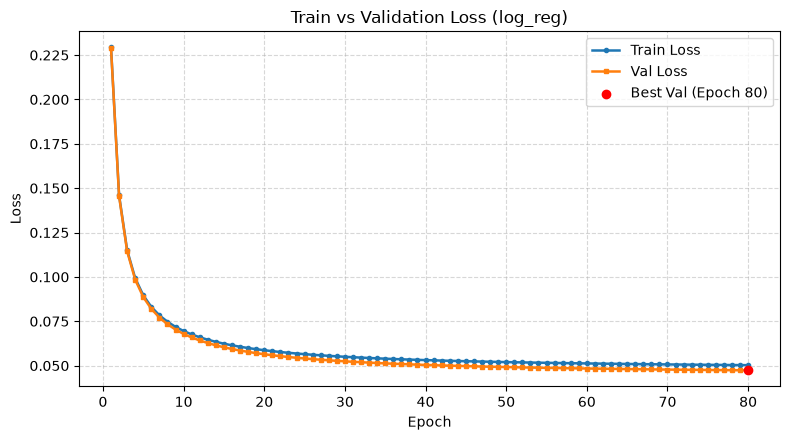

In [28]:
train_hist = np.asarray(log_reg.get_history(), dtype=np.float64)
val_hist = np.asarray(log_reg.get_val_hist(), dtype=np.float64)

print(f"Train epochs: {len(train_hist)} | Val epochs: {len(val_hist)}")

if len(train_hist) > 0:
    print(f"Train loss: đầu={train_hist[0]:.6f} -> cuối={train_hist[-1]:.6f} | min={train_hist.min():.6f}")
    print("Train loss hữu hạn:", np.isfinite(train_hist).all())

if len(val_hist) > 0:
    best_idx = int(np.argmin(val_hist))
    best_epoch = best_idx + 1
    best_val_loss = val_hist[best_idx]

    print(f"Val loss  : đầu={val_hist[0]:.6f} -> cuối={val_hist[-1]:.6f} | min={best_val_loss:.6f} (epoch {best_epoch})")
    print("Val loss hữu hạn  :", np.isfinite(val_hist).all())

    if val_hist[-1] > best_val_loss:
        print(f"Cảnh báo: Val loss tăng sau epoch {best_epoch} ({best_val_loss:.6f} -> {val_hist[-1]:.6f}).")

epochs = np.arange(1, len(train_hist) + 1)
plt.figure(figsize=(8, 4.5))
if len(train_hist) > 0:
    plt.plot(epochs, train_hist, marker="o", markersize=3, linewidth=1.8, label="Train Loss")
if len(val_hist) == len(train_hist) and len(val_hist) > 0:
    plt.plot(epochs, val_hist, marker="s", markersize=3, linewidth=1.8, label="Val Loss")
    best_idx = int(np.argmin(val_hist))
    plt.scatter([best_idx + 1], [val_hist[best_idx]], color="red", zorder=5, label=f"Best Val (Epoch {best_idx + 1})")

plt.title("Train vs Validation Loss (log_reg)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
thresholds = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
y_true = y_val.astype(int)

print(f"{'Thresh':>7} | {'Pred_1':>7} | {'TP':>5} | {'Precision':>9} | {'Recall':>8} | {'F1':>8}")
print("-" * 58)

for th in thresholds:
    preds = (val_probs >= th).astype(int)
    tp = int(np.sum((preds == 1) & (y_true == 1)))
    fp = int(np.sum((preds == 1) & (y_true == 0)))
    fn = int(np.sum((preds == 0) & (y_true == 1)))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

    print(f"{th:7.2f} | {int(preds.sum()):7d} | {tp:5d} | {precision:9.4f} | {recall:8.4f} | {f1:8.4f}")

 Thresh |  Pred_1 |    TP | Precision |   Recall |       F1
----------------------------------------------------------
   0.05 |    1681 |   266 |    0.1582 |   0.7964 |   0.2640
   0.10 |     723 |   221 |    0.3057 |   0.6617 |   0.4182
   0.15 |     421 |   176 |    0.4181 |   0.5269 |   0.4662
   0.20 |     273 |   145 |    0.5311 |   0.4341 |   0.4778
   0.30 |     146 |    90 |    0.6164 |   0.2695 |   0.3750
   0.40 |     101 |    73 |    0.7228 |   0.2186 |   0.3356
   0.50 |      66 |    55 |    0.8333 |   0.1647 |   0.2750
   0.60 |      42 |    38 |    0.9048 |   0.1138 |   0.2021
   0.70 |      25 |    25 |    1.0000 |   0.0749 |   0.1393
   0.80 |      14 |    14 |    1.0000 |   0.0419 |   0.0805
   0.90 |       8 |     8 |    1.0000 |   0.0240 |   0.0468


In [29]:
log_reg.save("logreg_model_1.npz")

'logreg_model_1.npz'

In [32]:
import numpy as np
import pandas as pd

test_proc = pd.read_csv("DataSolve/output/test_processed.csv")
sub = pd.read_csv("sample_submission.csv")

# Kiểm tra thứ tự id nếu cả hai đều có cột id
if "id" in test_proc.columns and "id" in sub.columns:
    assert (test_proc["id"] == sub["id"]).all(), "Thứ tự id không khớp sample_submission.csv!"

X_test = np.asanyarray(test_proc[feature_lists], dtype=np.float64)
test_probs = log_reg.predict_proba(X_test)

target_col = sub.columns[1]
sub[target_col] = test_probs

# Kiểm tra không có NaN / inf trước khi lưu
assert len(sub) == 299984
assert not sub[target_col].isna().any()
assert np.isfinite(sub[target_col]).all()

sub.to_csv("logistic_result/submission.csv", index=False)
print("Đã xuất submission.csv thành công:", sub.shape)
print("Phân bố xác suất test (min / mean / max):", test_probs.min(), test_probs.mean(), test_probs.max())
print(sub.head())

Đã xuất submission.csv thành công: (299984, 2)
Phân bố xác suất test (min / mean / max): 0.00017136785079897838 0.01860298252213034 0.9987107657055574
       id  is_fraud
0  699960  0.001054
1  699961  0.001566
2  699962  0.040996
3  699963  0.003324
4  699964  0.004953
